<a href="https://colab.research.google.com/github/Panlyzar/project_suui2/blob/main/SUI_CV5__SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📒 CVIČENÍ 5. -  SVM
---
V tomto cvičení si prakticky vyzkoušíme zajímavý a univezální ML model - a to **SVM (Support Vector Machine)**. Jedná se o složitější *model učení s učitelem* 👨‍🏫 který je určen především pro klasifikaci, ale zvládne například i regresní úlohy. Původně byl tento algoritmus navržen pouze pro binární klasifikaci ⚫⚪, ale lze rozšířit i pro potřeby multi-class klasifikace.  






## 🧩 SVM klasifikace
SVM **klasifikuje** data dělením do skupin pomocí **hyperroviny**. Hyperrovina je obecně nějaká rovina (v dvoudimenzionálním prostoru je to přímka; v trojrozměrném prostoru je to plocha a tak dále), která nejlépe odděluje různé třídy dat. Zde se objevují dva důležité pojmy: **podpůrné (support) vektory** a **vzdálenost od roviny (margin)**.

**Podpůrné vektory:** Jsou to data, která leží na okrajích (hranici) mezi třídami. Jsou klíčová pro definování hyperroviny. Kdybychom odstranili libovolné z těchto dat, hyperrovina by se změnila.

**Marge:** Jedná se o vzdálenost mezi hyperrovinou a nejbližším datovým vzorkem. SVM se snaží najít hyperrovinu, která tuto marge maximalizuje, což znamená, že se snaží být co nejdále od nejbližších dat.


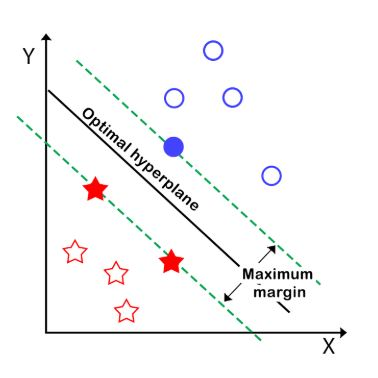

### 🪄 Transformace dat do vyšších dimenzí - "Kernelový trik"
Pokud dojde k situaci že data není možné čistě lineárně separovat - **není možné je oddělit přímkou**, je nutné použít tzv. kernelový trik a **převést data do vyšší dimenze**. Například z 2D do 3D dimenze a až poté je od sebe oddělit. Lépe to znázorní následující obrázek.

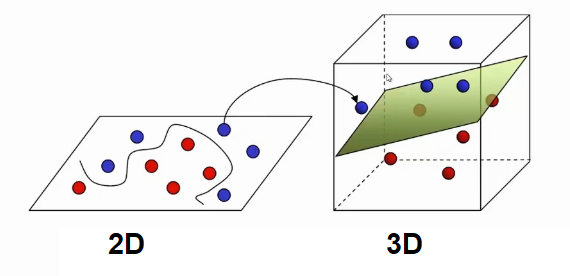

In [ ]:
# Import základních ML knihoven - best practices
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Knihovna pro práci s SVM
from sklearn import svm

## 👁️ ČÁST 1: Demonstrace SVM
V této části demonstruji SVM na *umělém datasetu* pro lepší vizualizaci principu.

In [ ]:
# Vytvoření falešných dat
X_fake = np.r_[np.random.randn(40, 2) - [2, 2], np.random.randn(40, 2) + [2, 2]]
y_fake = np.array([0] * 40 + [1] * 40)

X_fake.shape, y_fake.shape

((80, 2), (80,))

In [ ]:
X_fake[:5]

array([[-0.91465531, -0.54353709],
       [-2.67162368, -3.73840827],
       [-1.31849308, -2.44840533],
       [-3.91122685, -2.46258108],
       [-1.39989193, -1.87593986]])

In [ ]:
y_fake[:5]

array([0, 0, 0, 0, 0])

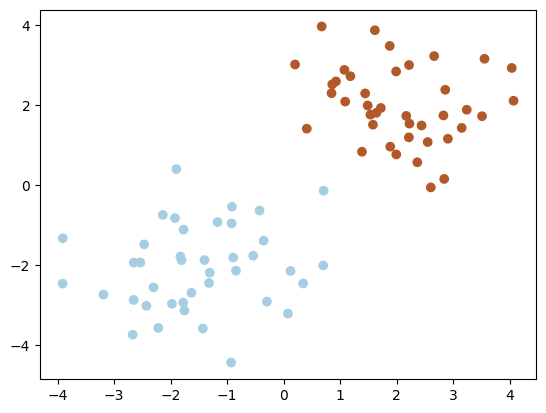

In [ ]:
plt.scatter(X_fake[:,0], X_fake[:,1], c=y_fake, cmap=plt.cm.Paired)

In [ ]:
# Použijeme SVC - Support Vector Classification
# Kernel může být 'linear', 'rbf', 'poly', atd.
clf = svm.SVC(kernel='linear')

In [ ]:
# trenuj
clf.fit(X_fake, y_fake)

SVC(kernel='linear')

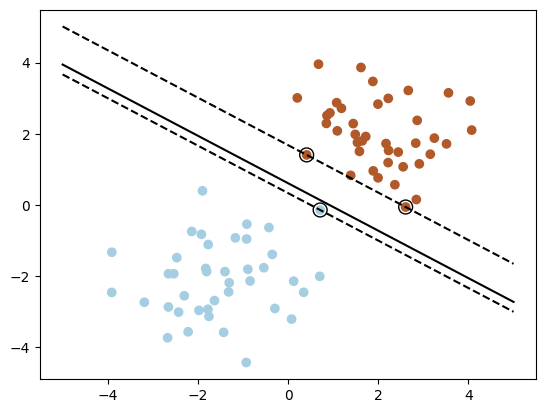

In [ ]:
#vizualizace SVM - vykresli hyperrovinu (zde přímku) a support vectors

# Parametry hyperroviny
w = clf.coef_[0]
a = -w[0] / w[1]
xx = np.linspace(-5, 5)
yy = a * xx - (clf.intercept_[0]) / w[1]

# Nastavení support vectors
b = clf.support_vectors_[0]
yy_down = a * xx + (b[1] - a * b[0])
b = clf.support_vectors_[-1]
yy_up = a * xx + (b[1] - a * b[0])

# Vykreslení bodů a hyperroviny
plt.scatter(X_fake[:,0], X_fake[:,1], c=y_fake, cmap=plt.cm.Paired)
plt.plot(xx, yy, 'k-')
plt.plot(xx, yy_down, 'k--')
plt.plot(xx, yy_up, 'k--')

# Zvýrazni body které jsou support vectors
plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
            s=100, facecolors='none', edgecolors='k')
plt.show()

In [ ]:
clf.score(X_fake, y_fake)

1.0

## 📃 ČÁST 2: Příprava dat: Moons
---
Dataset **Make Moons** je synteticky generovaná dvousložková datová sada pro **binární klasifikaci**. Vyznačuje se tvarem dvou **propletených půlměsíců**, což ji činí **nelineárně separovatelnou**.

Je to ideální volba pro **vizuální demonstraci** algoritmů, které zvládají složité hranice, zejména **Support Vector Machine (SVM) s jádrem RBF (Radial Basis Function)**.

* **Typ dat:** Syntetická, generovaná
* **Dimenze (Features):** 2 (X a Y souřadnice)
* **Počet tříd (Target):** 2 (0 a 1)
---

**Účel datasetu:**

Tato sada slouží k názorné ukázce:

1.  **Kernel Trick (Jádrový trik):** Demonstruje, proč **Lineární SVM selže** a je nutné použít nelineární jádro.
2.  **Vliv $\gamma$ (Gamma):** Protože data tvoří křivky, $\gamma$ (koeficient jádra) má zásadní vliv na **složitost a hladkost** rozhodovací hranice.
    * **Vysoká $\gamma$:** Hranice se stává **zubatou**, kopíruje jednotlivé body (overfitting).
    * **Nízká $\gamma$:** Hranice je **příliš hladká** a nedokáže přesně oddělit křivky (underfitting).
3.  **Vliv $C$ (Regulační parametr):** Lze sledovat, jak $C$ kontroluje **kompromis** mezi hladkou hranicí (vyšší margin) a tolerancí chyb (body spadající za margin).

---

**Popis Featur (Rysů):**

Dataset je navržen tak, aby měl jen 2 vstupní rysy, což umožňuje přímou vizualizaci jako bodový graf:

| Feature | Popis | Typ |
| :--- | :--- | :--- |
| **Feature 1 (X)** | Horizontální souřadnice bodu. | Numerická |
| **Feature 2 (Y)** | Vertikální souřadnice bodu. | Numerická |

#### Cílová Proměnná:

| Target | Popis | Typ |
| :--- | :--- | :--- |
| **Třída** | Označuje, ke kterému z propletených půlměsíců bod patří (0 nebo 1). | Binární |

In [ ]:
from sklearn.datasets import make_moons
# Načtení datasetu Make Moons
moons, labels = make_moons(n_samples=1000, noise=0.25, random_state=42)
moons.shape, labels.shape

((1000, 2), (1000,))

In [ ]:
moons[0]

array([-0.14176498,  0.55823629])

In [ ]:
labels[0]

np.int64(1)

In [ ]:
# Převod na DataFrame
df = pd.DataFrame(moons, columns=['Feature_1 (x)', 'Feature_2 (y)'])
df['Target'] = labels
df.head()

,Feature_1 (x),Feature_2 (y),Target
0,-0.141765,0.558236,1
1,1.197966,-0.303995,1
2,0.759391,0.110250,1
3,0.023315,-0.603563,1
4,-0.807980,0.548466,0


### 🔭 Explorační analýza

In [ ]:
df.describe()

,Feature_1 (x),Feature_2 (y),Target
count,1000.000000,1000.000000,1000.00000
mean,0.496266,0.243301,0.50000
std,0.901882,0.549014,0.50025
min,-1.556552,-1.129576,0.00000
25%,-0.132968,-0.199042,0.00000
50%,0.509394,0.239193,0.50000
75%,1.110611,0.693493,1.00000
max,2.715678,1.608788,1.00000


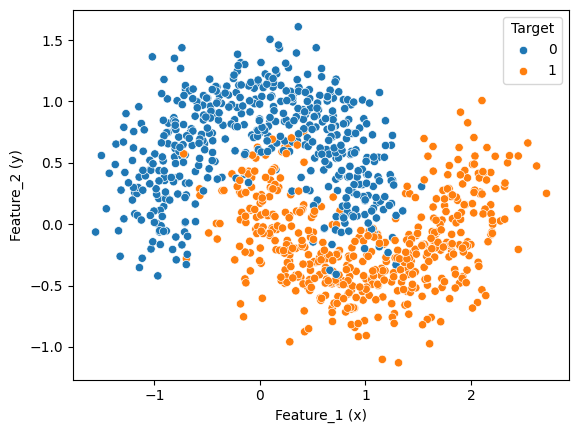

In [ ]:
# Plot Feature_1 (x)	Feature_2 (y)
sns.scatterplot(data=df, x='Feature_1 (x)', y='Feature_2 (y)', hue='Target')
plt.show()

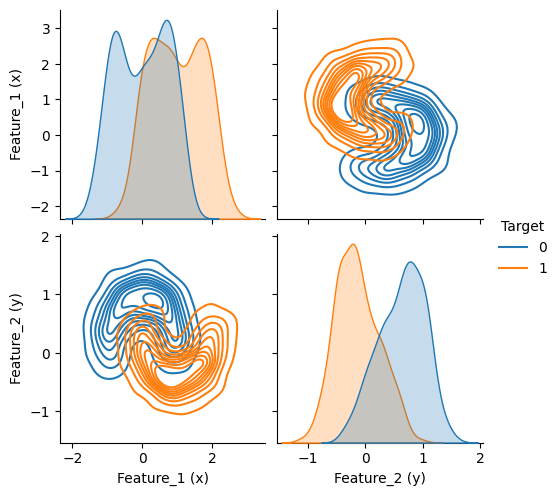

In [ ]:
sns.pairplot(df, kind="kde", hue="Target")

## ✂️ Rozdělení a úprava dat
Jako vstupy `X` použijeme vygenerované půlměsíce (neboli `moons`) a jako výstupy `y` použijeme binární reprezentaci třídy, neboli `labels`.

**Přestože je dataset již předrozdělen na vstupy a výstupy, je třeba jej rozdělit na trénovací a testovací množinu train/test. Také je nutné data normalizovat.**

### 🧠 Úkol 1: Rozděl data na X,y, normalizuj a vytvoř testovací a trénovací množinu v poměru 20/80

In [ ]:
# rozdělení na vstupy a výstupy: X a y
X = ???
y = ???

In [ ]:
# normalizace dat:
from sklearn.preprocessing import minmax_scale
X_norm = ???

SyntaxError: invalid syntax (ipython-input-4242240213.py, line 3)

In [ ]:
# rozdělení dat na train/test:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = ???

In [ ]:
# ověř tvar testovací a trénovací množiny pomocí shape:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

In [ ]:
# Udělej si náhhled dat - prvních 5 záznamů
???

## ⭐ Vytvoření modelu
Dataset je připraven, nyní nám stačí vytvořit, natrénovat a otestovat model.  

Vytvoříme a natrénujteme model `SVM` (`SVC` - Support Vector Classification) pomocí metody `fit`. Jako `kernel` použijte 'linear' a `C` nastavte na 10.0.
Více informací naleznete zde: [sklearn: SVC](https://scikit-learn.org/dev/modules/generated/sklearn.svm.SVC.html)


In [ ]:
# Knihovna pro práci s SVM
from sklearn import svm
# Použijeme SVC - Classificator
clf = svm.SVC(kernel="linear", C=10.0)

### 💪 Trénování modelu

In [ ]:
# natrénuj model
clf.fit(X_train, y_train)

SVC(C=10.0, kernel='linear')

### ✅ Testování modelu
Model otestujeme klasickou funkcí `score` nebo externí metrikou.

In [ ]:
# testování modelu
clf.score(X_test, y_test)

0.84

### 📊 Vykreslení SVM rozdělovacích hranic:
Funkce pro vykreslení rozdělovací roviny SVN modelu.



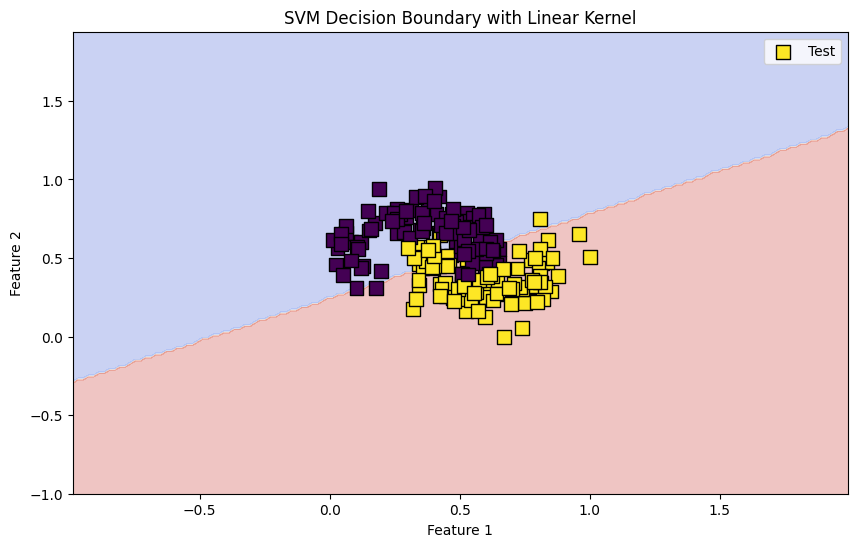

In [ ]:
# Očekávám 2D rozdělení dat na X a y, respektive X/y_train/test

# Define the grid to plot decision boundaries
x_min, x_max = X_test[:, 0].min() - 1, X_test[:, 0].max() + 1
y_min, y_max = X_test[:, 1].min() - 1, X_test[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
          np.arange(y_min, y_max, 0.02))

# Predict on the grid to obtain the decision boundary
Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot decision boundary and training points
plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, marker='s', s=100, edgecolor='k', label="Test")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("SVM Decision Boundary with Linear Kernel")
plt.legend()
plt.show()


### 🧠 ÚKOL 3:
Zkuste změnit nastavení modelu tak aby dokázal lépe rozdělit dataset a měl **vyšší skore**. Přemýšlejte jestli jsme použili vhodnou bázi (`linear`).





In [ ]:
#řešení úkolu č.3

## 🧭 Prozkoumání dalších modelů
Prozkoumej další možnosti modelu a vliv nastavení hyperparametrů, porovnej SVM s jinými modely (DTC, k-Means).


### 🧪 Zkoumání vlivu hyperparametrů

Experimentální zkoumání jaký vliv budou mít hyperparametry (C, kernel atd.) na výkonnost modelu.

In [ ]:
hyperparams = { "C":[0.1, 1, 10, 100 ,1000], "kernel":["linear", "rbf"] }

In [ ]:
# create parametr grid from hyperparams
from sklearn.model_selection import ParameterGrid

param_grid = ParameterGrid(hyperparams)
print(list(param_grid))

[{'C': 0.1, 'kernel': 'linear'}, {'C': 0.1, 'kernel': 'rbf'}, {'C': 1, 'kernel': 'linear'}, {'C': 1, 'kernel': 'rbf'}, {'C': 10, 'kernel': 'linear'}, {'C': 10, 'kernel': 'rbf'}, {'C': 100, 'kernel': 'linear'}, {'C': 100, 'kernel': 'rbf'}, {'C': 1000, 'kernel': 'linear'}, {'C': 1000, 'kernel': 'rbf'}]


In [ ]:
best_score = 0.0
best_params = None

for param in param_grid:
  clf = svm.SVC(**param)
  clf.fit(X_train, y_train)
  score = clf.score(X_test, y_test)
  if score > best_score:
    best_score = score
    best_params = param
  print(param, clf.score(X_test, y_test))

print("Best score: ", best_score)
print("Best params: ", best_params)

{'C': 0.1, 'kernel': 'linear'} 0.815
{'C': 0.1, 'kernel': 'rbf'} 0.91
{'C': 1, 'kernel': 'linear'} 0.83
{'C': 1, 'kernel': 'rbf'} 0.965
{'C': 10, 'kernel': 'linear'} 0.84
{'C': 10, 'kernel': 'rbf'} 0.965
{'C': 100, 'kernel': 'linear'} 0.84
{'C': 100, 'kernel': 'rbf'} 0.97
{'C': 1000, 'kernel': 'linear'} 0.84
{'C': 1000, 'kernel': 'rbf'} 0.97
Best score:  0.97
Best params:  {'C': 100, 'kernel': 'rbf'}


✍ *Vsuvka:* Hledání ideálních hyperparametrů může zabrat nějaký čas... ⏰

In [ ]:
# Vykresli graf SVM pro nejlepší hyperparametry


### 🧠 ÚKOL 4:
Které hyperparametry ještě můžeme použít a optimalizovat?

In [ ]:
#řešení úkolu č.4


In [ ]:
# Vykresli graf SVM pro tvé nejlepší hyperparametry